# Magic state distillation: eight T states to one CCZ state

> **In short.**
> * **The setting.** A fault-tolerant computer makes gates outside the Clifford group, such as $T$ and CCZ, by consuming *magic states*, which come out of the hardware noisy. *Distillation* turns several noisy magic states into fewer, better ones: it runs them through a small code and keeps a run only when its checks pass. L. Yeh's thesis (Section 6.5, "Magic state distillation", Eqs. (6.47) to (6.49)) shows in ZX how the transversal CCZ of the [[8,3,2]] code (see [TransversalCCZ.ipynb](TransversalCCZ.ipynb)) turns eight $T$ and $T^\dagger$ magic states into one CCZ magic state, $\mathrm{CCZ}|{+}{+}{+}\rangle$.
> * **The protocol.** The logical state $|{+}{+}{+}\rangle$ of the [[8,3,2]] code (x, y, z in $|+\rangle$ and the encoder of Eq. (6.27)); $T$ on four qubits and $T^\dagger$ on the other four (in a factory each consumes one magic state; here they are gates); the encoder's CNOTs in reverse order; then the five qubits that are not x, y, z measured, the thesis's qubit 8 in the X basis and its qubits 1, 2, 3, 5 in the Z basis. The three qubits x, y, z are kept when all five results are 0.
> * **What the tool finds, from the gates alone.** Questions 1 to 3: the $T$ layer prepares $\mathrm{CCZ}|{+}{+}{+}\rangle$ in the code, decoding takes it out unchanged, the five results are 0 in every noiseless run, and the whole protocol prepares $\mathrm{CCZ}|{+}{+}{+}\rangle$ in every run. Where it goes: seven phase gadgets on three $|+\rangle$, the same state as CCZ applied to $|{+}{+}{+}\rangle$. The thesis's form, Eq. (6.48), decodes the eight magic states directly: on the runs whose results are all 0 it is the same map, but its results are not fixed, and each changes the state by a $T$-type phase.
> * **Why it distils.** For $Z$ errors on the eight magic states, independent with probability $p$: every single error is caught by the checks, every pair passes them and changes the state, so the state kept is wrong with probability $28p^2$ to leading order (all 256 patterns tried by the tool).
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders; a phase gadget is a red dot joined to several green ones, with a green leaf carrying its phase ($7\pi/4$ is $-\pi/4$).
> * Eqs. (6.48) and (6.49) as the thesis draws them, level by level: [MagicStateDistillationStepByStep.ipynb](MagicStateDistillationStepByStep.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CCZ, CNOT, HAD, T, Measurement
from zxqec.qprogram import QProgram, pauli_errors
from zxqec.gpf import equal_for_all_assignments, phases_modulo, reduce_gpf, reduce_modulo
from zxqec.spacetime import draw_program

# as in TransversalCCZ.ipynb: qubit k is the thesis's qubit [8, 7, 6, 4, 1, 2, 3, 5][k]; x, y, z are qubits 1, 2, 3
WIRES = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 0: 7}          # drawn in the thesis's order of wires
GHZ = [CNOT(0, 4), CNOT(0, 5), CNOT(0, 6), CNOT(0, 7)]
FROM_X = [CNOT(1, 4), CNOT(1, 6), CNOT(1, 7), CNOT(0, 1)]
FROM_Y = [CNOT(2, 4), CNOT(2, 5), CNOT(2, 7), CNOT(0, 2)]
FROM_Z = [CNOT(3, 4), CNOT(3, 5), CNOT(3, 6), CNOT(0, 3)]
P = [T(1), T(2), T(3), T(4), T(5, adjoint=True), T(6, adjoint=True), T(7, adjoint=True), T(0, adjoint=True)]
P_DAGGER = [T(1, adjoint=True), T(2, adjoint=True), T(3, adjoint=True), T(4, adjoint=True), T(5), T(6), T(7), T(0)]
DECODE = FROM_Z[::-1] + FROM_Y[::-1] + FROM_X[::-1] + GHZ[::-1]
# the thesis's qubit 8 in the X basis (result c[0]), its qubits 1, 2, 3, 5 in the Z basis (c[1] to c[4])
CHECK = [HAD(0), Measurement(0, 0)] + [Measurement(q, k + 1) for k, q in enumerate((4, 5, 6, 7))]

## 1. The protocol

Seven stages: the GHZ state and the CNOTs from x, y and z (the encoder, here with x, y, z in $|+\rangle$), the $T$ layer, the decoding CNOTs, and the measurements. One level up: encoding, the $T$ layer, and decoding with the checks.

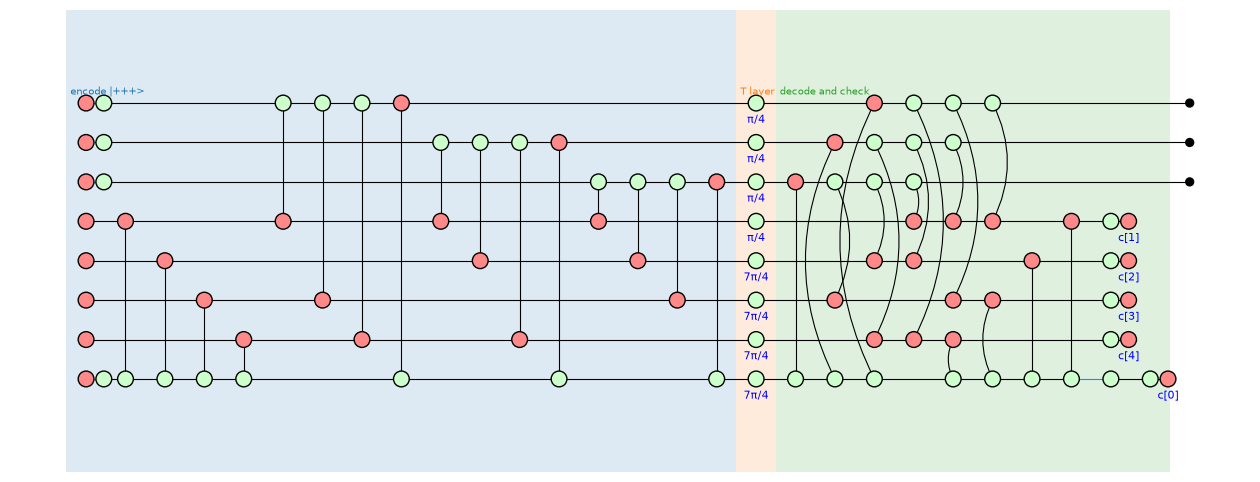

In [2]:
p = QProgram(8, bits=5, mapping=WIRES, initial_states={q: '0' if q >= 4 else '+' for q in range(8)})
for gates, name in ((GHZ, 'GHZ'), (FROM_X, 'from x'), (FROM_Y, 'from y'), (FROM_Z, 'from z'), (P, 'T layer'),
                    (DECODE, 'decode'), (CHECK, 'check')):
    c = Circuit(8, bit_amount=5)
    for gate in gates:
        c.add_gate(gate)
    p.add_circuit(c, name=name)
level = p.group_stages([(0, 3, 'encode |+++>', 'state preparation'), (4, 4, 'T layer', 'transversal gate'),
                        (5, 6, 'decode and check', 'decoder')])
draw_program(p, level=level, show_time=False, labels=False, figsize=(16, 6))

## 2. Questions 1 to 3

The level-up table. Encoded, $|{+}{+}{+}\rangle$ is a stabilizer state, so the tool reads it as a code with no logical qubit (`[[8,0]]`): the state is fixed. After the $T$ layer the qubits are in the [[8,3,2]] code again, holding a state that is not a stabilizer state; the layer prepares $\mathrm{CCZ}|{+}{+}{+}\rangle$ in the code, and decoding brings it out on x, y and z unchanged.

In [3]:
print(p.summary(level))
print("\nthe whole protocol:", p.logical_action().verdict())

block               role               code before  code after                         logical action     every run?  checks
0 encode |+++>      state preparation  none         [[8,0,?]]                          a non-zero scalar  yes         ok
1 T layer           transversal gate   [[8,0,?]]    [[8,3,2]]                          prepares CCZ|+++>  yes         ok
2 decode and check  decoder            [[8,3,2]]    [[1,1,1]] + [[1,1,1]] + [[1,1,1]]  I                  yes         ok

Block 0 'encode |+++>' (state preparation) -- stages 0, 1, 2, 3
  code before: no qubits
  code after:  [[8,0,?]] on qubits 0,1,2,3,4,5,6,7
  logical action: deterministic: every run implements a non-zero scalar
  ok      a non-zero scalar

Block 1 'T layer' (transversal gate) -- stages 4
  code before: [[8,0,?]] on qubits 0,1,2,3,4,5,6,7
  code after:  [[8,3,2]] on qubits 0,1,2,3,4,5,6,7 (non-Clifford logical content)
  logical action: deterministic: every run implements prepares CCZ|+++>
  ok      implem

The five results are fixed: each is 0 in every noiseless run (`c[0]`, the X result, is one of the detectors too). `c[0]` is listed as *frame*, because the reduced diagram still has $Z$ on two qubits when `c[0]` is 1; written modulo the detectors, those corrections are 0.

In [4]:
report = p.measurement_report()
print(report)
print("\ndetectors:", [str(d) for d in report.detectors])
print("the frame modulo the detectors:", [(pauli, str(reduce_modulo(phase, report.detectors))) for pauli, phase in report.frame])

5 measurements in the whole diagram; Pauli frame: Z(c[0]), Z(c[0])
1 frame; 4 fixed
5 detectors (5 of them internal); outcome space of the diagram: 5 forced + 0 steering the map + 0 gauge = 5
outcome  stage  qubit  pos  t   fate   why
c[1]     6      4      3    26  fixed  always 0: nothing in the protocol can change it
c[2]     6      5      4    26  fixed  always 0: nothing in the protocol can change it
c[3]     6      6      5    26  fixed  always 0: nothing in the protocol can change it
c[4]     6      7      6    26  fixed  always 0: nothing in the protocol can change it
c[0]     6      0      7    27  frame  the map depends on it: Z correction; Z correction

detectors: ['c[3]', 'c[2]', 'c[4] + c[3] + c[2]', 'c[1] + c[3] + c[2]', 'c[0]']
the frame modulo the detectors: [('Z', '0'), ('Z', '0')]


## 3. Where it goes

The tool's reduction of the whole protocol, written modulo the detectors: a Z-spider for each of x, y and z, joined to its output, and seven phase gadgets on them, $\pi/4$ on each one, $-\pi/4$ (shown $7\pi/4$) on each pair and $\pi/4$ on all three. That is CCZ applied to $|{+}{+}{+}\rangle$ (the three-legged H-box of Eq. (6.49)); the first line compares it with CCZ on $|{+}{+}{+}\rangle$ written as a program.

the same state as CCZ|+++>: True


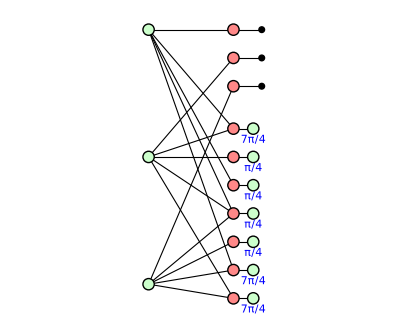

In [5]:
whole = reduce_gpf(p.quantum_graph())
state = QProgram(3, initial_states={0: '+', 1: '+', 2: '+'})
c = Circuit(3)
c.add_gate(CCZ(0, 1, 2))
state.add_circuit(c, name='CCZ')
print("the same state as CCZ|+++>:", equal_for_all_assignments(p.quantum_graph(), state.quantum_graph(), constraints=whole.detectors))
zx.draw_matplotlib(phases_modulo(whole.graph, whole.detectors), figsize=(5, 4))

### The thesis's form

Eq. (6.48) decodes the eight magic states directly: $|+\rangle$ on every qubit, $T^\dagger$ where the protocol has $T$ and $T$ where it has $T^\dagger$ (the adjoint of Eq. (6.47)), then the same decoding and checks. On the runs where all five results are 0 it is the same map as the protocol above. But nothing fixes its results here: the tool finds no detector, and each Z result negates the phase of one $T$-type gadget, a change that no Pauli correction undoes. So only the runs with all five results 0 can be kept; encoding $|{+}{+}{+}\rangle$ first, as above, makes every noiseless run one of them.

In [6]:
direct = QProgram(8, bits=5, mapping=WIRES, initial_states={q: '+' for q in range(8)})
for gates, name in ((P_DAGGER, 'magic states'), (DECODE, 'decode'), (CHECK, 'check')):
    c = Circuit(8, bit_amount=5)
    for gate in gates:
        c.add_gate(gate)
    direct.add_circuit(c, name=name)
print("the same map where every result is 0:",
      equal_for_all_assignments(direct.quantum_graph(), p.quantum_graph(), constraints=whole.detectors))
print(direct.measurement_report())

the same map where every result is 0: True
5 measurements in the whole diagram; Pauli frame: Z(c[0])
  gadget signs (not Pauli corrections): phase 1/4 negated when c[3] = 1, phase 1/4 negated when c[2] = 1, phase 7/4 negated when c[1] = 1, phase 1/4 negated when c[4] = 1
5 frame
0 detectors (0 of them internal); outcome space of the diagram: 0 forced + 5 steering the map + 0 gauge = 5
outcome  stage  qubit  pos  t   fate   why
c[1]     2      4      3    10  frame  the map depends on it: negates the phase-7/4 gadget (a conditional rotation, not a Pauli)
c[2]     2      5      4    10  frame  the map depends on it: negates the phase-1/4 gadget (a conditional rotation, not a Pauli)
c[3]     2      6      5    10  frame  the map depends on it: negates the phase-1/4 gadget (a conditional rotation, not a Pauli)
c[4]     2      7      6    10  frame  the map depends on it: negates the phase-1/4 gadget (a conditional rotation, not a Pauli)
c[0]     2      0      7    11  frame  the map depend

## 4. Why it distils

A noisy magic state is modelled here as the right state with a $Z$ error, with probability $p$, independently for each of the eight (what twirling the states would make the noise; the twirling itself is not modelled). A $Z$ error on a magic state is a $Z$ error after the $T$ gate it is used for. `pauli_errors` tries every pattern of $Z$ errors after the $T$ layer (stage 4), 256 of them, and sorts each: *caught* (no run passes the checks), *harmless* (runs pass and the state is right), or *wrong* (runs pass and the state is wrong).

In [7]:
errors = pauli_errors(p, 4, range(8), letter='Z')
print(errors)
for prob in (1e-2, 1e-3):
    print("p = {}: a run passes with probability {:.4f}; the state kept is wrong with probability {:.3e} (28 p^2 = {:.3e})"
          .format(prob, errors.acceptance(prob), errors.output_error(prob), 28 * prob ** 2))

Z errors after stage 4 on qubits 0, 1, 2, 3, 4, 5, 6, 7:
  weight  patterns  caught  harmless  wrong
       0         1       0         1      0
       1         8       8         0      0
       2        28       0         0     28
       3        56      56         0      0
       4        70       0        14     56
       5        56      56         0      0
       6        28       0         0     28
       7         8       8         0      0
       8         1       0         1      0
lowest weight that passes the checks and changes the output: 2 (28 pattern(s)); output error 28 p^2 to leading order
p = 0.01: a run passes with probability 0.9254; the state kept is wrong with probability 2.849e-03 (28 p^2 = 2.800e-03)
p = 0.001: a run passes with probability 0.9921; the state kept is wrong with probability 2.806e-05 (28 p^2 = 2.800e-05)


Read with the code: one $Z$ error anticommutes with the code's only X check ($X$ on all eight qubits), so the X result `c[0]` is 1 and the run is thrown away; so is any odd number. Two errors commute with it and pass, and no Z check of the code is on two qubits, so every pair changes the logical state: 28 patterns, the leading term $28p^2$. Of the 70 patterns of four errors, 14 are Z checks of the code and change nothing: the four corners of a face, of two opposite edges, or the four corners with an even (or an odd) number of 1s.

## Summary

* The tool finds the protocol to prepare $\mathrm{CCZ}|{+}{+}{+}\rangle$ in every noiseless run, with its five check results always 0.
* Its reduction is the three-legged H-box of Eq. (6.49) as seven phase gadgets, the same state as CCZ on $|{+}{+}{+}\rangle$; the thesis's form, decoding the magic states directly, agrees with it on the runs that pass.
* With independent $Z$ errors of probability $p$ on the eight magic states, a single error is always caught and the state kept is wrong with probability $28p^2$ to leading order.

What is not covered: the noise is a model (independent $Z$ errors; twirling, and errors in the Clifford gates and measurements, are not modelled); each $T$ is a gate here, not the injection of a magic state (see [SteaneTInjection.ipynb](SteaneTInjection.ipynb) for an injection); and the factory's output is not used by anything here.